In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Step 1: Dataset Loading & Initial Exploration

In [2]:
# Loading the dataset
df_drcat = pd.read_csv("./data/train_v2_drcat_02.csv")
df_ai_2026 = pd.read_csv("./data/ai_vs_human_text_2026.csv")
df_ai_human = pd.read_csv("./data/AI_Human.csv")

In [3]:
datasets = {
    'AI_Human': df_ai_human,
    'train_v2_drcat_02': df_drcat,
    'ai_vs_human_text_2026': df_ai_2026
}

for name, df in datasets.items():
    print(f"The {name} dataset has {df.shape[0]:,} rows and {df.shape[1]} columns")

The AI_Human dataset has 487,235 rows and 2 columns
The train_v2_drcat_02 dataset has 44,868 rows and 5 columns
The ai_vs_human_text_2026 dataset has 2,000 rows and 9 columns


In [4]:
print("AI Human Dataset")
display(df_ai_human.head(5))
print("Train V2 DRCAT Dataset")
display(df_drcat.head(5))
print("AI vs Human text 2026 Dataset")
display(df_ai_2026.head(5))

AI Human Dataset


,text,generated
0,Cars. Cars have been around since they became ...,0.0
1,Transportation is a large necessity in most co...,0.0
2,"""America's love affair with it's vehicles seem...",0.0
3,How often do you ride in a car? Do you drive a...,0.0
4,Cars are a wonderful thing. They are perhaps o...,0.0


Train V2 DRCAT Dataset


,text,label,prompt_name,source,RDizzl3_seven
0,Phones\n\nModern humans today are always on th...,0,Phones and driving,persuade_corpus,False
1,This essay will explain if drivers should or s...,0,Phones and driving,persuade_corpus,False
2,Driving while the use of cellular devices\n\nT...,0,Phones and driving,persuade_corpus,False
3,Phones & Driving\n\nDrivers should not be able...,0,Phones and driving,persuade_corpus,False
4,Cell Phone Operation While Driving\n\nThe abil...,0,Phones and driving,persuade_corpus,False


AI vs Human text 2026 Dataset


,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation
3,TXT_0004,human,human,academic,This paper examines genomic research breakthro...,genomic research breakthroughs,49,16.3,template+human_variation
4,TXT_0005,ai,gpt-4o,academic,Existing literature on student debt crisis has...,student debt crisis,42,10.8,style_simulation


In [5]:
for name, df in datasets.items():
    print(f"--- {name} ---")
    print(df.info())
    print()

--- AI_Human ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 487235 entries, 0 to 487234
Data columns (total 2 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   text       487235 non-null  object 
 1   generated  487235 non-null  float64
dtypes: float64(1), object(1)
memory usage: 7.4+ MB
None

--- train_v2_drcat_02 ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44868 entries, 0 to 44867
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   text           44868 non-null  object
 1   label          44868 non-null  int64 
 2   prompt_name    44868 non-null  object
 3   source         44868 non-null  object
 4   RDizzl3_seven  44868 non-null  bool  
dtypes: bool(1), int64(1), object(3)
memory usage: 1.4+ MB
None

--- ai_vs_human_text_2026 ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column    

In [6]:
for name, df in datasets.items():
    print(f"--- {name} ---")
    print(df.dtypes)
    print()

--- AI_Human ---
text          object
generated    float64
dtype: object

--- train_v2_drcat_02 ---
text             object
label             int64
prompt_name      object
source           object
RDizzl3_seven      bool
dtype: object

--- ai_vs_human_text_2026 ---
text_id                 object
label                   object
source_model            object
domain                  object
text_content            object
topic_hint              object
word_count               int64
avg_sentence_length    float64
generation_method       object
dtype: object



# Step 2: Exploring the datasets

In [7]:
# Check for missing values
for name, df in datasets.items():
    print(f"--- {name} ---")
    print("Missing values:\n", df.isnull().sum())
    print("Fully duplicated rows:", df.duplicated().sum())
    print()

--- AI_Human ---
Missing values:
 text         0
generated    0
dtype: int64
Fully duplicated rows: 0

--- train_v2_drcat_02 ---
Missing values:
 text             0
label            0
prompt_name      0
source           0
RDizzl3_seven    0
dtype: int64
Fully duplicated rows: 0

--- ai_vs_human_text_2026 ---
Missing values:
 text_id                0
label                  0
source_model           0
domain                 0
text_content           0
topic_hint             0
word_count             0
avg_sentence_length    0
generation_method      0
dtype: int64
Fully duplicated rows: 0



In [8]:
# Check for duplicate values
text_cols = {
    'AI_Human': 'text',
    'train_v2_drcat_02': 'text',
    'ai_vs_human_text_2026': 'text_content',
}

dup_summary = {}
for name, col in text_cols.items():
    df = datasets[name]
    stripped = df[col].str.strip()
    total = len(df)
    unique = stripped.nunique()
    dup_summary[name] = {'total': total, 'unique': unique, 'duplicates': total - unique}
    print(f"{name}: {total:,} rows, {unique:,} unique texts, {total - unique:,} duplicate rows "
          f"({(total - unique) / total:.1%})")

AI_Human: 487,235 rows, 465,247 unique texts, 21,988 duplicate rows (4.5%)
train_v2_drcat_02: 44,868 rows, 44,864 unique texts, 4 duplicate rows (0.0%)
ai_vs_human_text_2026: 2,000 rows, 966 unique texts, 1,034 duplicate rows (51.7%)


# Step 3: Renaming key data columns to common points

In [9]:
df_ai_2026 = df_ai_2026.rename(columns={'text_content': 'text'})

df_ai_human['is_ai'] = df_ai_human['generated'].astype(int)
df_drcat['is_ai']    = df_drcat['label'].astype(int)
df_ai_2026['is_ai']  = (df_ai_2026['label'] == 'ai').astype(int)

datasets = {
    'AI_Human': df_ai_human,
    'train_v2_drcat_02': df_drcat,
    'ai_vs_human_text_2026': df_ai_2026,
}

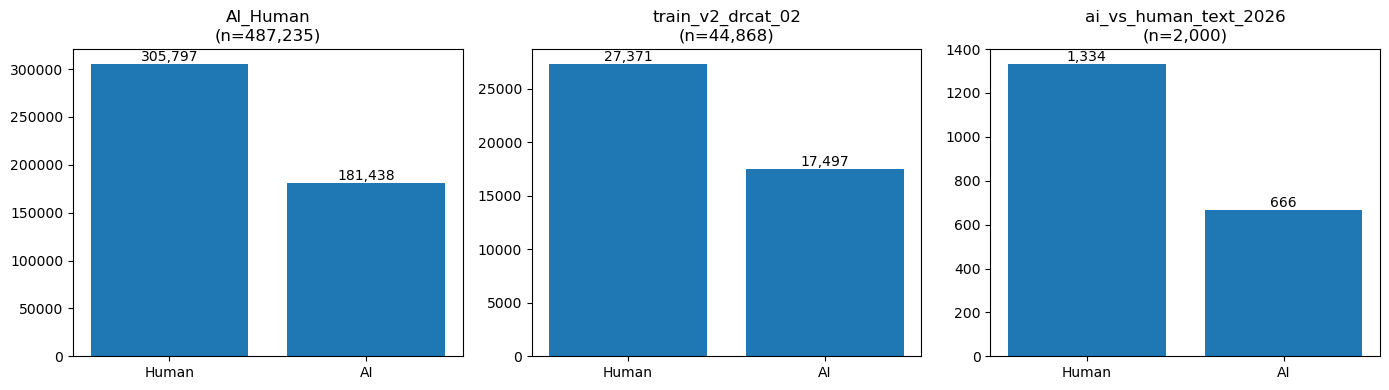

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, df) in zip(axes, datasets.items()):
    counts = df['is_ai'].value_counts().sort_index()
    ax.bar(['Human', 'AI'], counts.values)
    ax.set_title(f"{name}\n(n={len(df):,})")
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v:,}", ha='center', va='bottom')
plt.tight_layout()
plt.show()

In [11]:
for df in datasets.values():
    df['char_length'] = df['text'].str.len()
    df['word_count']  = df['text'].str.split().str.len()

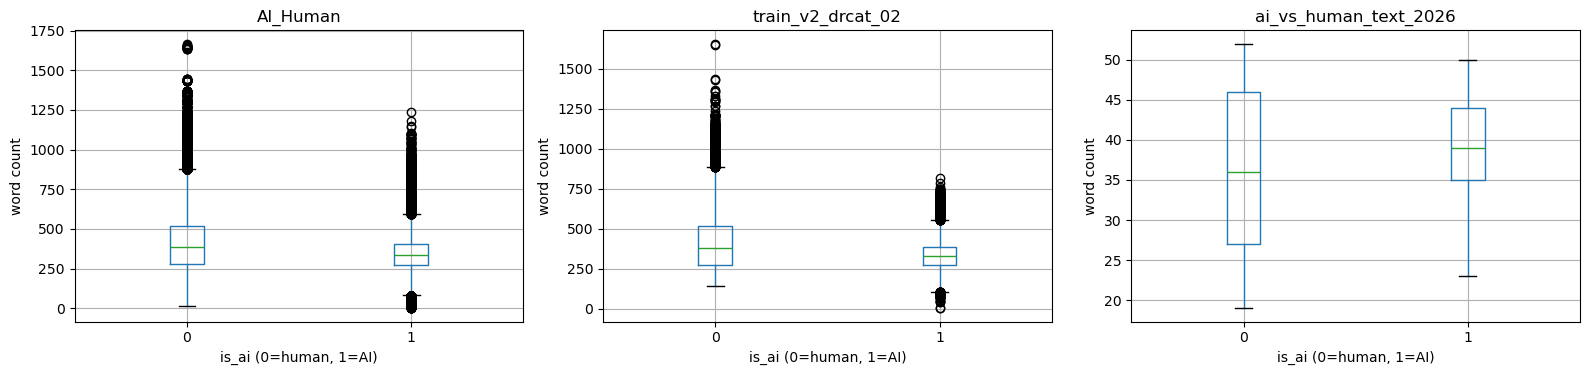

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, df) in zip(axes, datasets.items()):
    df.boxplot(column='word_count', by='is_ai', ax=ax)
    ax.set_title(name)
    ax.set_xlabel('is_ai (0=human, 1=AI)')
    ax.set_ylabel('word count')
plt.suptitle('')
plt.tight_layout()
plt.show()

In [13]:
# Summary table stats
for name, df in datasets.items():
    print(f"--- {name} ---")
    print(df.groupby('is_ai')['word_count'].describe())
    print()

--- AI_Human ---
          count       mean         std   min    25%    50%    75%     max
is_ai                                                                    
0      305797.0  421.98518  186.870962  14.0  281.0  389.0  520.0  1668.0
1      181438.0  344.40653  117.031491   0.0  274.0  337.0  403.0  1238.0

--- train_v2_drcat_02 ---
         count        mean         std    min    25%    50%    75%     max
is_ai                                                                     
0      27371.0  418.283146  189.285918  143.0  274.0  383.0  519.0  1656.0
1      17497.0  329.398983   94.256529    4.0  274.0  328.0  386.0   818.0

--- ai_vs_human_text_2026 ---
        count       mean       std   min   25%   50%   75%   max
is_ai                                                           
0      1334.0  36.508246  9.662008  19.0  27.0  36.0  46.0  52.0
1       666.0  38.004505  7.007513  23.0  35.0  39.0  44.0  50.0



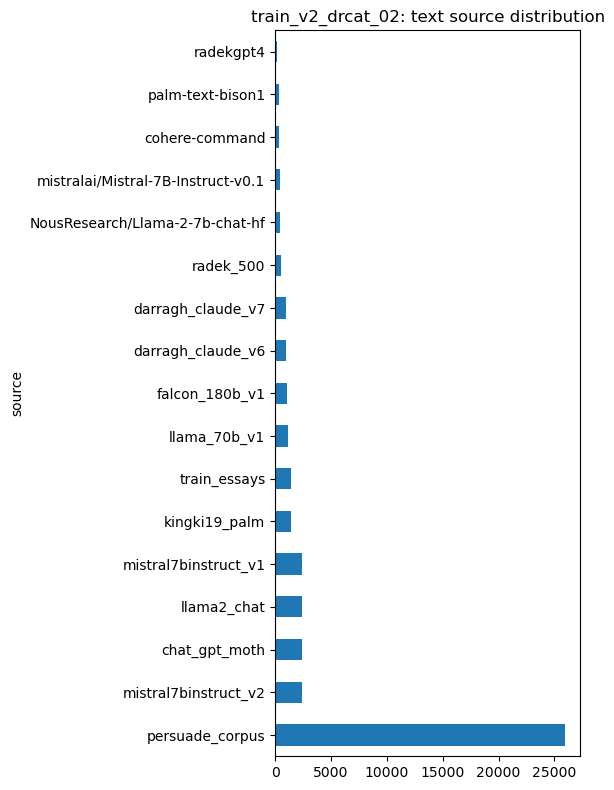

In [14]:
# train_v2_drcat_02: which generator/source produced
df_drcat['source'].value_counts().plot(kind='barh', figsize=(6, 8))
plt.title('train_v2_drcat_02: text source distribution')
plt.tight_layout()
plt.show()

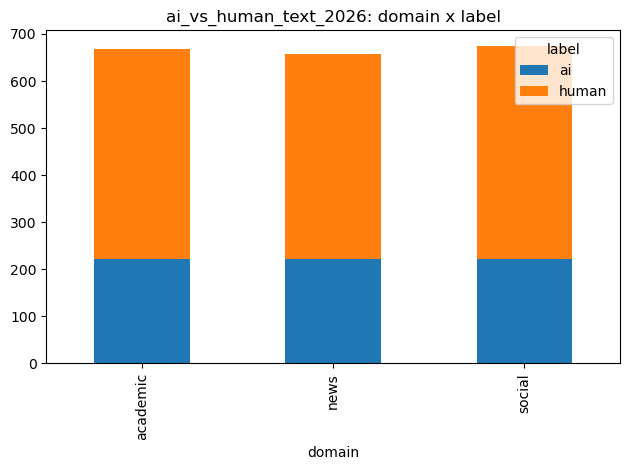

In [15]:
# ai_vs_human_text_2026: domain x label
pd.crosstab(df_ai_2026['domain'], df_ai_2026['label']).plot(kind='bar', stacked=True)
plt.title('ai_vs_human_text_2026: domain x label')
plt.tight_layout()
plt.show()

# Step 4: Cross-dataset duplicate check: AI_Human vs train_v2_drcat_02

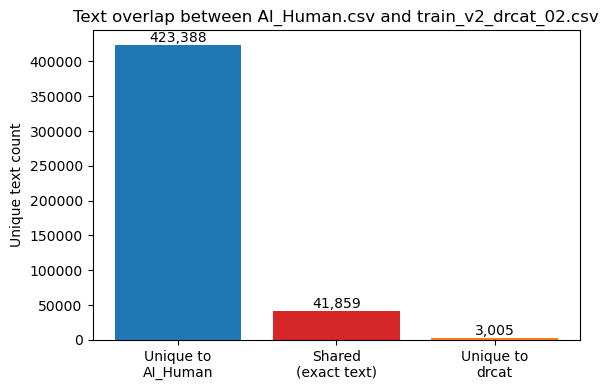

In [16]:
# Compare AI_Human vs DRCAT duplicates
ai_human_set = set(df_ai_human['text'].str.strip())
drcat_set    = set(df_drcat['text'].str.strip())

only_ai_human = len(ai_human_set - drcat_set)
only_drcat    = len(drcat_set - ai_human_set)
shared        = len(ai_human_set & drcat_set)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Unique to\nAI_Human', 'Shared\n(exact text)', 'Unique to\ndrcat'],
              [only_ai_human, shared, only_drcat],
              color=['tab:blue', 'tab:red', 'tab:orange'])
ax.bar_label(bars, fmt='{:,.0f}')
ax.set_ylabel('Unique text count')
ax.set_title('Text overlap between AI_Human.csv and train_v2_drcat_02.csv')
plt.tight_layout()
plt.show()

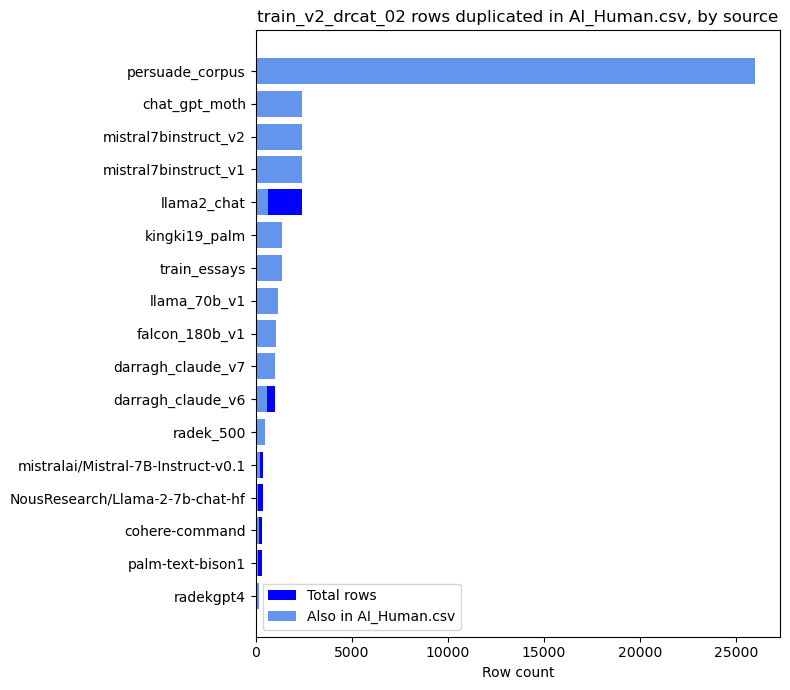

In [17]:
drcat_dup_mask = df_drcat['text'].str.strip().isin(ai_human_set)

overlap_by_source = (
    df_drcat.assign(is_dup=drcat_dup_mask)
    .groupby('source')['is_dup']
    .agg(overlap='sum', total='count')
    .sort_values('total')
)

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(overlap_by_source.index, overlap_by_source['total'], color='blue', label='Total rows')
ax.barh(overlap_by_source.index, overlap_by_source['overlap'], color='cornflowerblue', label='Also in AI_Human.csv')
ax.set_xlabel('Row count')
ax.set_title('train_v2_drcat_02 rows duplicated in AI_Human.csv, by source')
ax.legend()
plt.tight_layout()
plt.show()

In [18]:
# Step 1: keep only the essential columns, and tag which dataset each row came from
df_ai_human_core = df_ai_human[['text', 'is_ai']].copy()
df_ai_human_core['text'] = df_ai_human_core['text'].str.strip()
df_ai_human_core['source_dataset'] = 'AI_Human'

df_drcat_core = df_drcat[['text', 'is_ai']].copy()
df_drcat_core['text'] = df_drcat_core['text'].str.strip()
df_drcat_core['source_dataset'] = 'drcat'


In [19]:
# Step 2: remove duplicate essays within each dataset (keep the first copy)
# whichever copy appears first wins, the repeat is dropped.
before = len(df_ai_human_core)
df_ai_human_core = df_ai_human_core.drop_duplicates(subset='text', keep='first')

before = len(df_drcat_core)
df_drcat_core = df_drcat_core.drop_duplicates(subset='text', keep='first')

In [20]:
# Step 3: remove drcat rows whose essay already exists in AI_Human
# (keeping AI_Human's copy, since it's the larger/original source)
ai_human_texts = set(df_ai_human_core['text'].str.strip())
before = len(df_drcat_core)
df_drcat_core = df_drcat_core[~df_drcat_core['text'].str.strip().isin(ai_human_texts)]
print(f"drcat: {before:,} -> {len(df_drcat_core):,} rows after removing rows already in AI_Human")

drcat: 44,864 -> 3,005 rows after removing rows already in AI_Human


In [21]:
# Step 4: combine into one clean dataset
df_combined = pd.concat([df_ai_human_core, df_drcat_core], ignore_index=True)

print(f"Combined dataset: {len(df_combined):,} rows")
print(df_combined['source_dataset'].value_counts())
print(df_combined['is_ai'].value_counts(normalize=True))

# Debugging: no duplicate essays should remain
remaining_dupes = df_combined['text'].str.strip().duplicated().sum()
print(f"Duplicate texts remaining: {remaining_dupes}")

before = len(df_combined)
df_combined = df_combined[df_combined['text'] != ''].reset_index(drop=True)
print(f"Combined: {before:,} -> {len(df_combined):,} rows after dropping empty texts")

Combined dataset: 468,252 rows
source_dataset
AI_Human    465247
drcat         3005
Name: count, dtype: int64
is_ai
0    0.609606
1    0.390394
Name: proportion, dtype: float64
Duplicate texts remaining: 0
Combined: 468,252 -> 468,251 rows after dropping empty texts


In [22]:
# Step 5: Feature Engineering
FUNCTION_WORDS = {
    'a', 'an', 'the', 'and', 'but', 'or', 'nor', 'for', 'so', 'yet', 'although', 'because',
    'since', 'unless', 'while', 'whereas', 'in', 'on', 'at', 'by', 'with', 'about', 'against',
    'between', 'into', 'through', 'during', 'before', 'after', 'above', 'below', 'to', 'from',
    'up', 'down', 'of', 'off', 'over', 'under', 'again', 'further', 'once', 'i', 'me', 'my',
    'myself', 'we', 'our', 'ours', 'ourselves', 'you', 'your', 'yours', 'yourself', 'yourselves',
    'he', 'him', 'his', 'himself', 'she', 'her', 'hers', 'herself', 'it', 'its', 'itself', 'they',
    'them', 'their', 'theirs', 'themselves', 'this', 'that', 'these', 'those', 'who', 'whom',
    'whose', 'which', 'what', 'am', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have',
    'has', 'had', 'having', 'do', 'does', 'did', 'doing', 'will', 'would', 'shall', 'should',
    'can', 'could', 'may', 'might', 'must', 'not', 'no', 'if', 'than', 'too', 'very', 'just',
    'also', 'only',
}

def engineer_text_features(df):
    df = df.copy()
    words = df['text'].str.split()

    df['word_count'] = words.str.len()
    df['char_length'] = df['text'].str.len()
    df['avg_word_length'] = df['char_length'] / df['word_count']
    df['sentence_count'] = df['text'].str.count(r'[.!?]+') + 1
    df['avg_sentence_length'] = df['word_count'] / df['sentence_count']
    df['unique_word_ratio'] = words.apply(lambda w: len(set(w)) / len(w) if len(w) > 0 else 0)
    df['punctuation_ratio'] = df['text'].str.count(r'[^\w\s]') / df['char_length']
    df['uppercase_ratio'] = df['text'].str.count(r'[A-Z]') / df['char_length']

    def stopword_ratio(text):
        w = [x.strip('.,!?;:"\'').lower() for x in text.split()]
        return sum(1 for x in w if x in FUNCTION_WORDS) / len(w) if w else 0.0
    df['stopword_ratio'] = df['text'].apply(stopword_ratio)

    return df

In [23]:
# Sample for speed — df_combined is 468k+ rows, word-level processing is slow at that scale
sample = df_combined.sample(20000, random_state=42)
sample = engineer_text_features(sample)

feature_cols = ['word_count', 'avg_word_length', 'sentence_count', 'avg_sentence_length',
                 'unique_word_ratio', 'punctuation_ratio', 'uppercase_ratio', 'stopword_ratio']
sample[feature_cols].describe()

,word_count,avg_word_length,sentence_count,avg_sentence_length,unique_word_ratio,punctuation_ratio,uppercase_ratio,stopword_ratio
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,392.617900,5.771529,21.515100,19.261020,0.511882,0.021456,0.023478,0.438789
std,167.695865,0.488548,9.216356,8.748946,0.089672,0.010291,0.020151,0.059450
min,1.000000,1.000000,1.000000,1.000000,0.055147,0.000000,0.000000,0.000000
25%,280.000000,5.427326,15.000000,15.550000,0.451444,0.016775,0.012809,0.402062
50%,362.000000,5.701149,20.000000,18.192308,0.508296,0.020087,0.019549,0.443137
75%,469.000000,6.042931,26.000000,21.133333,0.568843,0.024296,0.029042,0.479790
max,1632.000000,8.962264,156.000000,329.000000,1.000000,1.000000,0.785914,0.647799


In [24]:
# Step 6: prepare the 2026 set as a holdout
df_2026_holdout = df_ai_2026[['text', 'is_ai']].copy()
df_2026_holdout['text'] = df_2026_holdout['text'].str.strip()
df_2026_holdout['source_dataset'] = 'ai_vs_human_text_2026'
df_2026_holdout = df_2026_holdout.drop_duplicates(subset='text', keep='first')

print(f"External holdout: {len(df_2026_holdout):,} rows")
print(df_2026_holdout['is_ai'].value_counts(normalize=True))

External holdout: 966 rows
is_ai
0    0.599379
1    0.400621
Name: proportion, dtype: float64


In [25]:
# Step 7: split the data for train/test
train_df, temp_df = train_test_split(
    df_combined, test_size=0.2, stratify=df_combined['is_ai'], random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['is_ai'], random_state=42
)

for name, split in [('Train', train_df), ('Val', val_df), ('Test', test_df)]:
    print(f"{name}: {len(split):,} rows, is_ai balance:\n{split['is_ai'].value_counts(normalize=True)}\n")

Train: 374,600 rows, is_ai balance:
is_ai
0    0.609608
1    0.390392
Name: proportion, dtype: float64

Val: 46,825 rows, is_ai balance:
is_ai
0    0.60961
1    0.39039
Name: proportion, dtype: float64

Test: 46,826 rows, is_ai balance:
is_ai
0    0.609597
1    0.390403
Name: proportion, dtype: float64



In [26]:
print("=== Final dataset summary ===")
print(f"Training pool (AI_Human + drcat, deduped): {len(df_combined):,} rows")
print(f"  Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")
print(f"External holdout (ai_vs_human_text_2026): {len(df_2026_holdout):,} rows")
print(f"No duplicate texts in combined set: {df_combined['text'].duplicated().sum() == 0}")

=== Final dataset summary ===
Training pool (AI_Human + drcat, deduped): 468,251 rows
  Train: 374,600 | Val: 46,825 | Test: 46,826
External holdout (ai_vs_human_text_2026): 966 rows
No duplicate texts in combined set: True
